In [11]:
#| include: false
from pathlib import Path
from datetime import timedelta
from dataclasses import asdict
from io import BytesIO
import hashlib
import json
import sys

import pandas as pd
import matplotlib
from IPython.display import display, Image
from pandas.testing import assert_frame_equal

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file() and (path / "src/dp_activity").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project repository.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
from dp_activity import StudyPeriod
from dp_activity.config import load_config
from dp_activity.cli import (
    build_download_command, _default_column_map,
    _default_classification_field_map, _snapshot_observation_end,
)
from dp_activity.repositories.raw_data_repository import RawDataRepository
from dp_activity.profiling.data_profiler import DataProfiler
from dp_activity.cleaning.permit_cleaner import PermitCleaner
from dp_activity.classification.rule_loader import RuleLoader
from dp_activity.classification.classifier import PermitClassifier
from dp_activity.validation.schema_validator import SchemaValidator
from dp_activity.validation.data_quality_validator import DataQualityValidator
from dp_activity.validation.classification_validator import ClassificationValidator
from dp_activity.features.period_features import add_period_features
from dp_activity.features.season_features import add_season_features
from dp_activity.features.processing_features import add_processing_features
from dp_activity.analysis.volume_analysis import VolumeAnalysis
from dp_activity.analysis.type_analysis import TypeAnalysis
from dp_activity.analysis.geography_analysis import GeographyAnalysis
from dp_activity.analysis.processing_analysis import ProcessingAnalysis
from dp_activity.analysis.rezoning_analysis import RezoningAnalysis
from dp_activity.analysis.seasonal_analysis import SeasonalAnalysis
from dp_activity.visualization.chart_factory import ChartFactory

pd.set_option("display.max_rows", 15)
pd.set_option("display.max_colwidth", 100)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.13.15 | pandas 2.2.3 | Matplotlib 3.10.8


In [12]:
#| include: false
SETTINGS_PATH = ROOT / "config/settings.yaml"
SNAPSHOT_FILENAME = "development_permits_residential_20261013_001726.parquet"
config = load_config(SETTINGS_PATH)
snapshot_path = config.raw_data_dir / SNAPSHOT_FILENAME
primary_date_field = config.raw["analysis"]["primary_date_field"]
source_date_field = next(source for source, target in _default_column_map().items() if target == primary_date_field)
expected_where = build_download_command(config).where
REVIEW_LIMIT = 5
repository = RawDataRepository(config.raw_data_dir)
raw = repository.load_snapshot(snapshot_path)
raw_before = raw.copy(deep=True)
sidecar_path = snapshot_path.with_suffix(snapshot_path.suffix + ".metadata.json")
metadata = json.loads(sidecar_path.read_text(encoding="utf-8"))
snapshot_sha256 = hashlib.sha256(snapshot_path.read_bytes()).hexdigest()
assert metadata["sha256"] == snapshot_sha256, "Snapshot checksum mismatch."
assert metadata["row_count"] == len(raw), "Snapshot row-count mismatch."
assert metadata["dataset_id"] == config.raw["data_source"]["dataset_id"]
query = metadata["query"]
if isinstance(query, str):
    query = json.loads(query)
assert query["where"] == expected_where, "Snapshot does not cover the configured query."
observation_end = _snapshot_observation_end(snapshot_path, None)
covered_periods = list(config.periods)
covered_labels = [period.name for period in covered_periods]
application_dates = pd.to_datetime(raw[source_date_field], errors="raise")
assert not raw.empty and application_dates.notna().all()
assert application_dates.dt.date.between(covered_periods[0].start, observation_end).all()
coverage_rows = []
for period in covered_periods:
    end = min(period.end, observation_end) if period.end else observation_end
    dates = application_dates.loc[application_dates.dt.date.between(period.start, end)]
    coverage_rows.append({
        "Period": period.name, "WindowStart": period.start, "WindowEnd": end,
        "ExposureDays": (end - period.start).days + 1, "AllPermitCount": len(dates),
        "FirstObservedApplication": dates.min(), "LastObservedApplication": dates.max(),
        "ContextOnly": period.end is None,
    })
coverage_table = pd.DataFrame(coverage_rows)
assert int(coverage_table["AllPermitCount"].sum()) == len(raw)
display(coverage_table)
display(pd.DataFrame([{
    "snapshot": snapshot_path.name, "records": len(raw),
    "retrieved_at_utc": metadata["retrieved_at_utc"],
    "snapshot_sha256": snapshot_sha256,
    "settings_sha256": hashlib.sha256(SETTINGS_PATH.read_bytes()).hexdigest(),
    "rules_sha256": hashlib.sha256(config.classification_rules_path.read_bytes()).hexdigest(),
}]))
print("Source-lag check: latest application date is", application_dates.max())
print("Retrieval horizon is a coverage convention, not proof of complete reporting.")

,Period,WindowStart,WindowEnd,ExposureDays,AllPermitCount,FirstObservedApplication,LastObservedApplication,ContextOnly
0,Before,2022-08-06,2024-08-05,731,16637,2022-08-06,2024-08-05,False
1,During,2024-08-06,2026-08-03,728,13866,2024-08-06,2026-08-03,False
2,Early Post-Repeal,2026-08-04,2026-10-13,71,1124,2026-08-04,2026-10-11,True


,snapshot,records,retrieved_at_utc,snapshot_sha256,settings_sha256,rules_sha256
0,development_permits_residential_20261013_001726.parquet,31627,2026-10-13 00:17:25.865806+00:00,fc7cdfad598ab894aa9eacb0cb396d4537070524d8ea8b78f4ad449b7da6e78d,1347050e4d80b133e5530e4703b9d031c8889f3b1555043316e597fae664e1db,ecc20ce16844c1dbe863594a8e451e2e5c1fd6663f4926de667df62a68ccc6cb


Source-lag check: latest application date is 2026-10-11 00:00:00
Retrieval horizon is a coverage convention, not proof of complete reporting.


In [13]:
#| include: false
analysis_settings = config.raw["analysis"]
column_map = _default_column_map()
processing_settings = analysis_settings["processing_time"]
cleaned = PermitCleaner(column_map, [primary_date_field, processing_settings["end_field"]]).clean(raw)
retained_mask = raw["address"].notna() & raw["address"].astype("string").str.strip().ne("")
address_excluded_records = raw.loc[~retained_mask].copy()
assert len(cleaned) + len(address_excluded_records) == len(raw)
assert cleaned.index.equals(raw.index[retained_mask])
rules = RuleLoader().load(config.classification_rules_path)
classification_settings = analysis_settings["classification"]
classified = PermitClassifier(rules, _default_classification_field_map(), unmatched_action=classification_settings["unmatched_action"], case_sensitive=classification_settings["case_sensitive"]).classify(cleaned)
classified_before_features = classified.copy(deep=True)
observation_end = _snapshot_observation_end(snapshot_path, None)
processing_settings = analysis_settings["processing_time"]
feature_periods = list(config.periods)

period_permits = add_period_features(
    classified,
    date_column=analysis_settings["primary_date_field"],
    periods=feature_periods,
    decision_date_column=processing_settings["end_field"],
)
season_permits = add_season_features(
    period_permits,
    date_column=analysis_settings["primary_date_field"],
    season_months={
        value.get("label", key): value["months"]
        for key, value in config.raw["seasons"].items()
    },
    analysis_windows=feature_periods,
    observation_end=observation_end,
)
featured = add_processing_features(
    season_permits,
    applied_date_column=processing_settings["start_field"],
    decision_date_column=processing_settings["end_field"],
    minimum_days=processing_settings.get("minimum_days", 0),
    observation_end=observation_end,
)
assert_frame_equal(classified, classified_before_features)
assert_frame_equal(featured[classified.columns], classified)
assert_frame_equal(season_permits[period_permits.columns], period_permits)
assert_frame_equal(featured[season_permits.columns], season_permits)
assert len(featured) == len(cleaned) and featured.index.equals(cleaned.index)
assert featured["Period"].isin(covered_labels).all()


residential_permits = featured.loc[featured["IncludeResidential"]].copy()
season_definitions = {
    value.get("label", key): value["months"]
    for key, value in config.raw["seasons"].items()
}
analysis_input = featured.copy(deep=True)
strategies = [
    VolumeAnalysis(covered_periods, date_column=primary_date_field, observation_end=observation_end),
    TypeAnalysis(period_order=covered_labels),
    ProcessingAnalysis(period_order=covered_labels, community_column="community"),
    RezoningAnalysis(),
    GeographyAnalysis(
        analysis_settings["community_analysis"]["minimum_baseline_count"],
        period_order=covered_labels, community_column="community", ward_column="ward",
    ),
    SeasonalAnalysis(covered_periods, season_months=season_definitions,
                     date_column=primary_date_field, observation_end=observation_end),
]
analysis_tables = {}
for strategy in strategies:
    results = strategy.run(residential_permits)
    if set(results) & set(analysis_tables):
        raise ValueError("Analysis output names must be unique.")
    analysis_tables.update(results)
assert_frame_equal(featured, analysis_input)

residential_count = len(residential_permits)
assert_frame_equal(residential_permits, featured.loc[featured["IncludeResidential"]])
for key in ("permit_volume", "monthly_volume", "seasonal_summary", "type_summary"):
    assert int(analysis_tables[key]["PermitCount"].sum()) == residential_count
    assert set(analysis_tables[key]["Period"].dropna()) == set(covered_labels)
assert int(analysis_tables["rezoning_summary"]["PeriodResidentialCount"].sum()) == residential_count


quality_report = pd.DataFrame([asdict(item) for item in DataQualityValidator().validate(featured, settings=config.raw["quality_checks"])])
schema_issues = SchemaValidator().validate(featured, required_columns=config.raw["quality_checks"]["required_columns"])
assert not any(issue.severity == "error" for issue in schema_issues)
classification_validation = ClassificationValidator().validate(featured, rules=rules)
assert_frame_equal(raw, raw_before)
PRIMARY = covered_labels[:2]
COLORS = ["#0072B2", "#D55E00"]
plt.rcParams.update({"figure.figsize": (11, 5), "font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
volume = analysis_tables["permit_volume"].set_index("Period")
primary_volume = volume.loc[PRIMARY]
count_change = (primary_volume.iloc[1]["PermitCount"] / primary_volume.iloc[0]["PermitCount"] - 1) * 100
rate_change = (primary_volume.iloc[1]["DP_Rate30"] / primary_volume.iloc[0]["DP_Rate30"] - 1) * 100
print(f"Ready: {len(raw):,} source rows; {len(address_excluded_records)} address exclusions; {len(residential_permits):,} residential applications.")

Ready: 31,627 source rows; 4 address exclusions; 18,015 residential applications.


---
title: Calgary development permit activity
---

## 1 · The question · 0:40 {.smaller .scrollable}

**How did application activity differ between the two study windows?**

- Before: August 6, 2022–August 5, 2024.
- During: August 6, 2024–August 3, 2026.
- Early Post-Repeal: August 4, 2026 onward; context only.

::: {.notes}
Introduce the project, the comparison, and the unit of observation. Explain that applications show activity in the planning process. They do not directly count dwelling units or completed homes.
:::

## 2 · Why this question matters · 0:55 {.smaller .scrollable}

Citywide rezoning provides a policy timeline against which to describe permit activity. Application records can reveal changes in volume, residential type, geography, and recorded decision duration.

Sources: [City rezoning information](https://www.calgary.ca/planning/projects/rezoning.html), [Land Use Bylaw](https://www.calgary.ca/planning/land-use/online-land-use-bylaw.html?sec=21P2024). The study-date definitions are recorded in [Methodology](../docs/METHODOLOGY.md).

::: {.notes}
Explain the configured policy dates and distinguish application dates from decision dates. State that other economic and policy conditions changed at the same time. The analysis measures an association with the study windows.
:::

## 3 · Data and study design · 1:05 {.smaller .scrollable}

**One row is one development permit application.** Periods use the application date. The frozen source includes residential and other applications; ordered classification rules define the residential subset.

Source: [City Development Permits dataset](https://data.calgary.ca/Business-and-Economic-Activity/Development-Permits/6933-unw5).

::: {.notes}
Identify City dataset 6933-unw5. Read the source and retained counts below. Explain why different exposure lengths require rates and why the short recent period has incomplete follow-up. Retrieval defines a coverage convention, not proof of complete reporting.
:::

In [14]:
#| echo: false
study_design = coverage_table[["Period", "WindowStart", "WindowEnd", "ExposureDays", "AllPermitCount"]].copy()
retained_counts = featured.groupby("Period", observed=True).size()
residential_counts = residential_permits.groupby("Period", observed=True).size()
study_design["RetainedApplications"] = study_design["Period"].map(retained_counts)
study_design["AddressExclusions"] = study_design["AllPermitCount"] - study_design["RetainedApplications"]
study_design["ResidentialApplications"] = study_design["Period"].map(residential_counts)
assert int(study_design["AllPermitCount"].sum()) == len(raw)
assert int(study_design["AddressExclusions"].sum()) == len(address_excluded_records)
assert int(study_design["ResidentialApplications"].sum()) == len(residential_permits)
display(study_design.rename(columns={"AllPermitCount": "SourceApplications"}))
print(f"Retrieved: {metadata['retrieved_at_utc']} | Latest application: {application_dates.max().date()}")

,Period,WindowStart,WindowEnd,ExposureDays,SourceApplications,RetainedApplications,AddressExclusions,ResidentialApplications
0,Before,2022-08-06,2024-08-05,731,16637,16636,1,9856
1,During,2024-08-06,2026-08-03,728,13866,13863,3,7603
2,Early Post-Repeal,2026-08-04,2026-10-13,71,1124,1124,0,556


Retrieved: 2026-10-13 00:17:25.865806+00:00 | Latest application: 2026-10-11


## 4 · From source records to analysis · 1:05 {.smaller .scrollable}

**Frozen snapshot → cleaning → classification → features → validation → residential summaries**

- Exclude blank/null addresses; retain literal undefine/undefined values.
- Preserve raw evidence and retained row indices.
- Apply ordered rules; review flags do not automatically exclude applications.
- Keep partial windows and processing eligibility visible.

::: {.notes}
Give the address-exclusion count from the previous table as a concrete effect of a cleaning rule. Explain that accessories and non-housing relaxations can qualify under the analytical residential definition. The review register includes provisional, fallback, review, and unmatched cases. Automated checks do not establish independent accuracy.
:::

In [15]:
#| echo: false
display(pd.DataFrame([{
    "Address exclusions": len(address_excluded_records),
    "Retained applications needing classification review": int(featured["ClassificationNeedsReview"].sum()),
    "Residential applications needing review": int(residential_permits["ClassificationNeedsReview"].sum()),
}]))
display(quality_report.loc[quality_report["status"].ne("pass"), ["check_name", "status", "affected_rows"]])

,Address exclusions,Retained applications needing classification review,Residential applications needing review
0,4,2657,539


,check_name,status,affected_rows
5,missing_decision_date,warn,7010
7,missing_community,warn,50
8,missing_coordinates,warn,50


## 5 · Volume and seasonality · 1:30 {.smaller .scrollable}

**Compare counts and exposure-adjusted activity together.** Months and seasons at policy boundaries can be partial.

::: {.notes}
Read the calculated count and rate differences below. Use the monthly chart to describe fluctuations rather than infer a policy mechanism. The appendix seasonal table compares pooled complete-season rates; the seasonal mix and elapsed years still differ. Grey recent data are context only.
:::

,PermitCount,ExposureDays,DP_Rate30
Period,,,
Before,9856,731,404.49
During,7603,728,313.31
Early Post-Repeal,556,71,234.93


During versus Before: -22.86% applications; -22.54% applications per 30 exposed days.


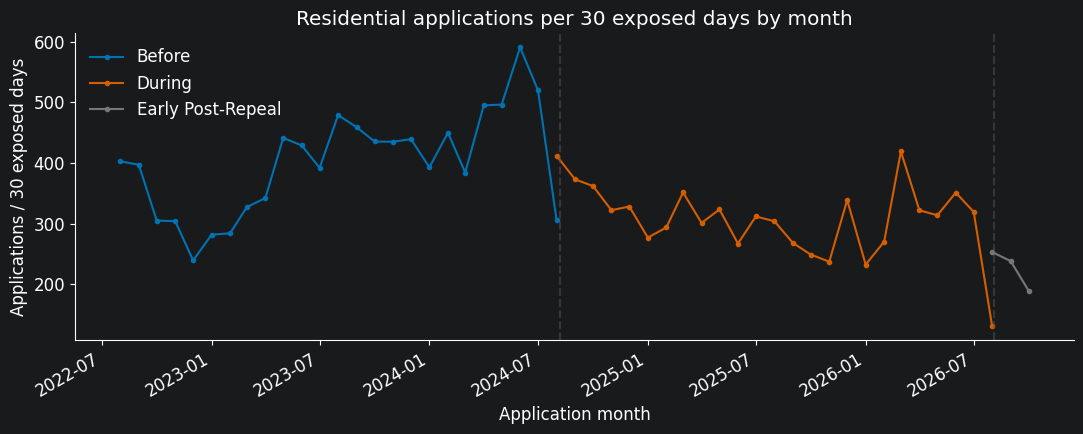

In [16]:
#| echo: false
display(volume[["PermitCount", "ExposureDays", "DP_Rate30"]].round(2))
print(f"During versus Before: {count_change:+.2f}% applications; {rate_change:+.2f}% applications per 30 exposed days.")
monthly = analysis_tables["monthly_volume"]
fig, ax = plt.subplots(figsize=(11, 4.5))
for label, color in zip(covered_labels, [*COLORS, "#777777"]):
    part = monthly.loc[monthly["Period"].eq(label)].sort_values("YearMonth")
    ax.plot(pd.to_datetime(part["YearMonth"]), part["DP_Rate30"].astype(float), marker=".", label=label, color=color)
for boundary in (covered_periods[1].start, covered_periods[2].start):
    ax.axvline(pd.Timestamp(boundary), color="#555555", linestyle="--", alpha=.5)
ax.set(title="Residential applications per 30 exposed days by month", ylabel="Applications / 30 exposed days", xlabel="Application month")
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
complete = analysis_tables["seasonal_summary"].loc[lambda table: table["IsCompleteSeason"] & table["Period"].isin(PRIMARY)]
season_rates = complete.groupby(["Period", "Season"], observed=True)[["PermitCount", "ExposureDays"]].sum()
season_rates["DP_Rate30"] = season_rates["PermitCount"] / season_rates["ExposureDays"] * 30


## 6 · Which residential types changed? · 1:15 {.smaller .scrollable}

**A change in a type's share can accompany a decline in its count.** Residential classifications include application activity beyond new dwellings.

::: {.notes}
Identify the largest count changes in the table and check their share changes. Explain that a share uses all residential applications in that period as its denominator. Describe rule-based categories as an analytical definition; do not translate them into new-home totals.
:::

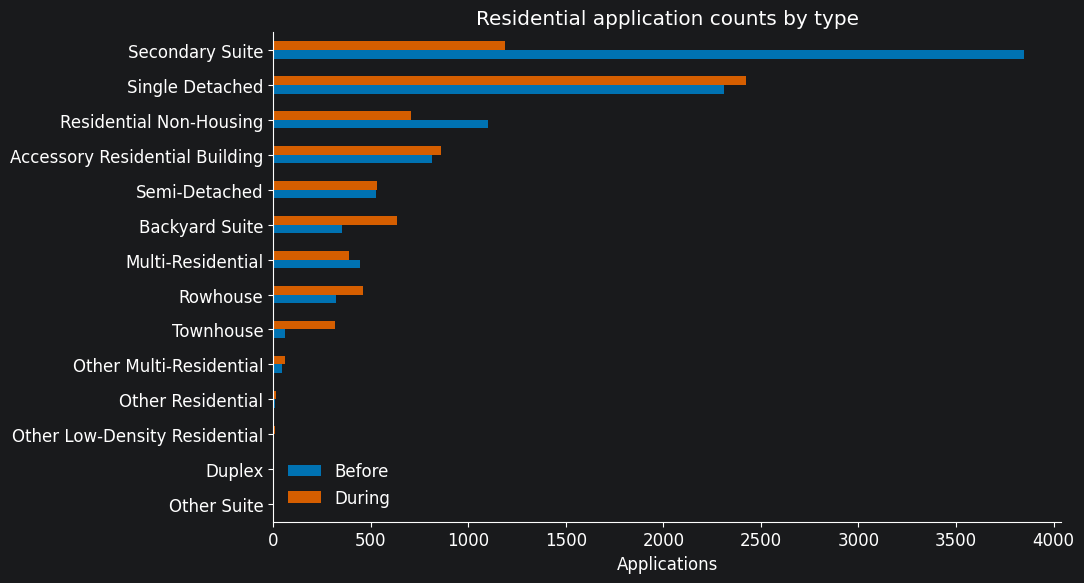

Largest type decline: Secondary Suite (-2,660 applications).
Largest type increase: Backyard Suite (+280 applications).


In [17]:
#| echo: false
type_table = analysis_tables["type_summary"]
type_counts = type_table.loc[type_table["Period"].isin(PRIMARY)].pivot(index="ResidentialType", columns="Period", values="PermitCount").reindex(columns=PRIMARY).fillna(0)
type_counts = type_counts.loc[type_counts.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 6))
type_counts.plot.barh(ax=ax, color=COLORS)
ax.set(title="Residential application counts by type", xlabel="Applications", ylabel="")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
type_comparison = type_table.loc[type_table["Period"].eq(PRIMARY[1]), ["ResidentialType", "PermitCount", "AbsoluteChange", "TypeShare", "ShareChangePercentagePoints"]].copy()
type_comparison["TypeShare"] = type_comparison["TypeShare"] * 100

largest_decline = type_comparison.loc[type_comparison["AbsoluteChange"].idxmin()]
largest_increase = type_comparison.loc[type_comparison["AbsoluteChange"].idxmax()]
print(f"Largest type decline: {largest_decline['ResidentialType']} ({int(largest_decline['AbsoluteChange']):+,} applications).")
print(f"Largest type increase: {largest_increase['ResidentialType']} ({int(largest_increase['AbsoluteChange']):+,} applications).")

## 7 · Where, and how long? · 1:35 {.smaller .scrollable}

**Local patterns can differ from the citywide total. Recorded durations depend on eligibility and follow-up.**

::: {.notes}
The geography chart ranks the ten largest absolute changes among known communities with adequate baselines. It is a subset, not the full city distribution. Source geography is used; geographic enrichment is disabled. Explain missing-location denominators and small-base warnings. Compare processing medians alongside eligible/ineligible counts; incomplete recent decisions can bias apparent speed.
:::

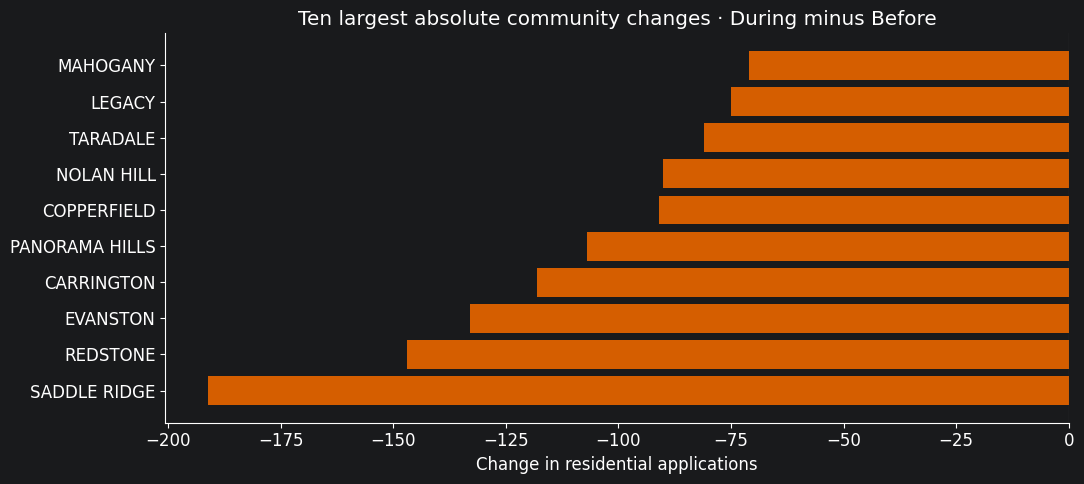

,Period,ValidCount,InvalidCount,MedianProcessingDays,Q1ProcessingDays,Q3ProcessingDays
0,Before,8231,1625,41,24,75
1,During,5812,1791,61,30,111
2,Early Post-Repeal,169,387,11,7,32


Geography uses source values; missing geography remains in analysis denominators.


In [18]:
#| echo: false
geography = analysis_tables["community_summary"]
changes = geography.loc[geography["Period"].eq(PRIMARY[1]) & ~geography["IsMissingGeography"] & ~geography["SmallBaselineWarning"]].copy()
changes = changes.loc[changes["AbsoluteChange"].abs().nlargest(10).index].sort_values("AbsoluteChange")
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(changes["Community"], changes["AbsoluteChange"].astype(float), color=[COLORS[1] if value < 0 else COLORS[0] for value in changes["AbsoluteChange"]])
ax.axvline(0, color="#555555", linewidth=.8)
ax.set(title="Ten largest absolute community changes · During minus Before", xlabel="Change in residential applications", ylabel="")
plt.tight_layout()
plt.show()
display(analysis_tables["processing_summary"][["Period", "ValidCount", "InvalidCount", "MedianProcessingDays", "Q1ProcessingDays", "Q3ProcessingDays"]].round(2))
print("Geography uses source values; missing geography remains in analysis denominators.")

## 8 · Conclusions and limits · 1:55 {.smaller .scrollable}

**What the evidence supports:** a descriptive comparison of residential application activity across the configured study periods.

- Volume: use the calculated counts and exposure-adjusted differences below.
- Composition and geography: inspect counts alongside shares and baseline sizes.
- Processing: interpret eligible durations with missing decisions and follow-up.

**What remains uncertain:** classification accuracy, source completeness, sensitivity to analytical definitions, and the contribution of confounding factors. Rates adjust calendar exposure; they do not adjust economic conditions or reporting lag. The recent post-repeal period is contextual.

::: {.notes}
Spend about 45 seconds on the verified volume result, 30 seconds connecting type/geographic variation to the citywide result, and 40 seconds on limitations and next steps. Cite the preserved source evidence, checksums, reconciliation, complete-season filtering, and visible eligibility warnings as safeguards actually performed. Independent classification review, sensitivity analyses, and Power BI reconciliation remain future work. End by saying that observed differences do not establish a causal policy effect.
:::

In [19]:
#| echo: false
print(f"Before: {int(volume.loc[PRIMARY[0], 'PermitCount']):,} residential applications.")
print(f"During: {int(volume.loc[PRIMARY[1], 'PermitCount']):,}; count difference {count_change:+.2f}%.")
print(f"Exposure-adjusted difference: {rate_change:+.2f}% per 30 exposed days.")
print(f"Early Post-Repeal: {int(volume.loc[covered_labels[2], 'PermitCount']):,} applications over {int(volume.loc[covered_labels[2], 'ExposureDays'])} days; context only.")
print("These observational differences do not establish a causal policy effect.")

Before: 9,856 residential applications.
During: 7,603; count difference -22.86%.
Exposure-adjusted difference: -22.54% per 30 exposed days.
Early Post-Repeal: 556 applications over 71 days; context only.
These observational differences do not establish a causal policy effect.


## Appendix · outside the 10-minute talk {.smaller .scrollable}

- [Complete-period exploration and full review register](02_complete_period_exploration.ipynb)
- [Verified findings and workflow guide](02_complete_period_exploration_explanation.md)
- [Methodology](../docs/METHODOLOGY.md), [bias and mitigation](../docs/BIAS_AND_MITIGATION.md), [classification configuration](../docs/CONFIGURATION.md)
- [References](../docs/REFERENCES.md), [Power BI plan](../docs/POWER_BI_PLAN.md)

To refresh: deliberately change the pinned filename, retain its sidecar, and rerun all cells. Check checksum, query, row reconciliation, classification status, eligible processing counts, and source geography before using the new findings. Current settings and rule hashes appear in preparation output. Quarto renders a local Reveal.js HTML deck from saved notebook output; no data workbooks are exported.

In [20]:
#| echo: false
print("Complete seasons only: pooled residential applications per 30 exposed days.")
display(season_rates["DP_Rate30"].unstack("Period").reindex(columns=PRIMARY).round(2))
print("During residential type shares and count changes:")
display(type_comparison.rename(columns={"TypeShare": "DuringSharePercent"}).sort_values("AbsoluteChange").round(2))

Complete seasons only: pooled residential applications per 30 exposed days.


Period,Before,During
Season,,
Fall,389.01,301.81
Spring,414.29,338.64
Summer,433.37,294.46
Winter,347.73,290.17


During residential type shares and count changes:


,ResidentialType,PermitCount,AbsoluteChange,DuringSharePercent,ShareChangePercentagePoints
24,Secondary Suite,1186,-2660,15.6,-23.42
22,Residential Non-Housing,705,-397,9.27,-1.91
17,Multi-Residential,389,-58,5.12,0.58
21,Other Suite,3,0,0.04,0.01
20,Other Residential,14,2,0.18,0.06
16,Duplex,7,2,0.09,0.04
18,Other Low-Density Residential,10,8,0.13,0.11
25,Semi-Detached,533,8,7.01,1.68
19,Other Multi-Residential,61,13,0.8,0.32
14,Accessory Residential Building,862,48,11.34,3.08
